# Decision Trees: Training and Visualization

## Project overview
Demonstrate how decision-tree models learn decision rules from data and how their decision boundaries can be visualized.

## Objectives
- Fit a decision-tree classifier
- Understand feature-based splits and decision boundaries
- Visualize model behavior on sample data
- Consider how tree depth affects overfitting

## Tools and approach
- **Language:** Python
- **Core libraries:** pandas, NumPy, Matplotlib/Seaborn, and scikit-learn or TensorFlow/Keras where used in the notebook
- **Workflow:** data inspection and preparation, model/technique exploration, and evaluation or visualization

**Methods covered:** DecisionTreeClassifier, feature selection, visualization, and classification-boundary inspection.

> **Reproducibility note:** Run the notebook from top to bottom. Dataset paths may need to be selected or updated to match the Kaggle dataset attached to your notebook. Results can vary with data splits, random seeds, and library versions.


In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import kagglehub

# Download latest version
path = kagglehub.dataset_download("uciml/iris")

print("Path to dataset files:", path)

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

Path to dataset files: /kaggle/input/iris


In [38]:
from pathlib import Path

IMAGES_PATH = Path("images") / "decision_trees"
IMAGES_PATH.mkdir(exist_ok=True, parents=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    file_path = IMAGES_PATH.joinpath(f"{fig_id}.{fig_extension}")
    
    if tight_layout:
        plt.tight_layout()
    
    plt.savefig(
        file_path,
        dpi=resolution,
        format=fig_extension
    )


# Training and Visualizing a Decision Tree

In [39]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier

# Load dataset as a DataFrame
iris_dataset = load_iris(as_frame=True)

# Select features
features = iris_dataset.data.loc[:, ["petal length (cm)", "petal width (cm)"]]
labels = iris_dataset.target

# Initialize and train the model
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=2
)
dt_model.fit(features.to_numpy(), labels)


DecisionTreeClassifier(max_depth=2, random_state=42)

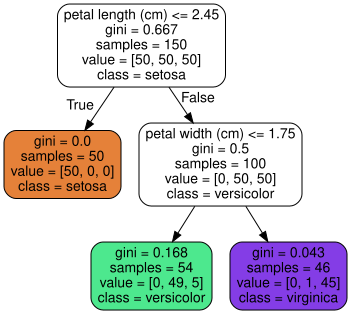

In [44]:
from sklearn.tree import export_graphviz
from graphviz import Source

dot_data = export_graphviz(
    tree_clf,
    feature_names=["petal length (cm)", "petal width (cm)"],
    class_names=iris.target_names,
    filled=True,
    rounded=True
)

Source(dot_data)


# Making Predictions

In [58]:
from sklearn.datasets import make_moons
X_moons, y_moons = make_moons(n_samples=150, noise=0.2, random_state=42)
tree_clf1 = DecisionTreeClassifier(random_state=42)
tree_clf2 = DecisionTreeClassifier(min_samples_leaf=5, random_state=42)
tree_clf1.fit(X_moons, y_moons)
tree_clf2.fit(X_moons, y_moons)

DecisionTreeClassifier(min_samples_leaf=5, random_state=42)

In [59]:
X_moons_test, y_moons_test = make_moons(n_samples=1000, noise=0.2,
                                        random_state=43)
tree_clf1.score(X_moons_test, y_moons_test)
tree_clf2.score(X_moons_test, y_moons_test)

0.92

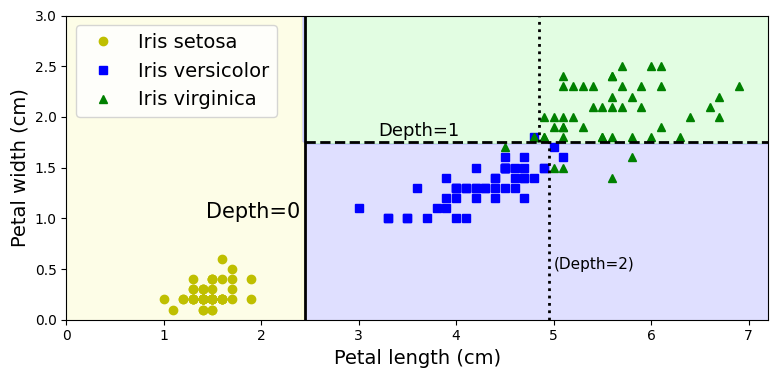

In [63]:
from matplotlib.colors import ListedColormap
from sklearn.tree import DecisionTreeClassifier

color_map = ListedColormap(["#fafab0", "#9898ff", "#a0faa0"])
fig, ax = plt.subplots(figsize=(8, 4))
x_vals = np.linspace(0, 7.2, 100)
y_vals = np.linspace(0, 3, 100)
xx, yy = np.meshgrid(x_vals, y_vals)

grid_points = np.column_stack((xx.ravel(), yy.ravel()))
predictions = tree_clf.predict(grid_points).reshape(xx.shape)

ax.contourf(xx, yy, predictions, alpha=0.3, cmap=color_map)
markers = ("yo", "bs", "g^")
for class_id, (label, marker) in enumerate(zip(iris.target_names, markers)):
    ax.plot(
        X_iris[y_iris == class_id, 0],
        X_iris[y_iris == class_id, 1],
        marker,
        label=f"Iris {label}"
    )
deep_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
deep_tree.fit(X_iris, y_iris)

t0, t1, t2_left, t2_right = deep_tree.tree_.threshold[[0, 2, 3, 6]]
ax.plot([t0, t0], [0, 3], "k-", lw=2)
ax.plot([t0, 7.2], [t1, t1], "k--", lw=2)
ax.plot([t2_left, t2_left], [0, t1], "k:", lw=2)
ax.plot([t2_right, t2_right], [t1, 3], "k:", lw=2)
ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Petal width (cm)")

ax.text(t0 - 0.05, 1.0, "Depth=0", ha="right", fontsize=15)
ax.text(3.2, t1 + 0.02, "Depth=1", va="bottom", fontsize=13)
ax.text(t2_left + 0.05, 0.5, "(Depth=2)", fontsize=11)

ax.axis([0, 7.2, 0, 3])
ax.legend()
save_fig("decision_tree_decision_boundaries_plot")
plt.show()


In [64]:
tree_clf.tree_

# Estimating Class Probabilities

In [69]:
proba = tree_clf.predict_proba([[5, 1.5]])
prediction = tree_clf.predict([[5, 1.5]])

proba.round(3)
prediction


array([1])

# Regularization Hyperparameters

In [70]:

X, y = make_moons(
    n_samples=150,
    noise=0.2,
    random_state=42
)
dt_default = DecisionTreeClassifier(random_state=42)
dt_leaf_constraint = DecisionTreeClassifier(
    min_samples_leaf=5,
    random_state=42
)
for model in (dt_default, dt_leaf_constraint):
    model.fit(X, y)


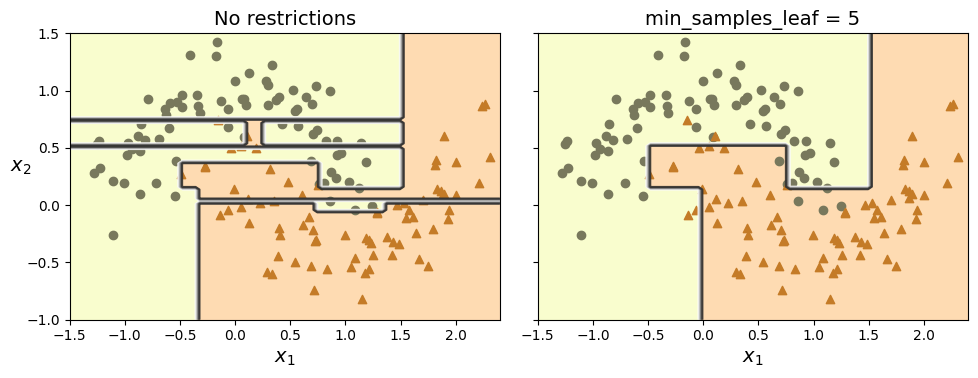

In [71]:
def draw_decision_regions(model, X, y, limits, cmap_name):
    # create grid
    xx, yy = np.meshgrid(
        np.linspace(limits[0], limits[1], 100),
        np.linspace(limits[2], limits[3], 100)
    )
    
    grid_points = np.column_stack([xx.ravel(), yy.ravel()])
    predictions = model.predict(grid_points).reshape(xx.shape)

    # plot decision regions
    plt.contourf(xx, yy, predictions, alpha=0.3, cmap=cmap_name)
    plt.contour(xx, yy, predictions, cmap="Greys", alpha=0.8)

    class_colors = {
        "Wistia": ["#78785c", "#c47b27"],
        "Pastel1": ["red", "blue"]
    }
    class_markers = ["o", "^"]

    # plot training points
    for label in [0, 1]:
        plt.scatter(
            X[y == label, 0],
            X[y == label, 1],
            c=class_colors[cmap_name][label],
            marker=class_markers[label]
        )

    plt.axis(limits)
    plt.xlabel(r"$x_1$")
    plt.ylabel(r"$x_2$", rotation=0)


fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

plt.sca(ax[0])
draw_decision_regions(
    model=tree_clf1,
    X=X_moons,
    y=y_moons,
    limits=[-1.5, 2.4, -1, 1.5],
    cmap_name="Wistia"
)
plt.title("No restrictions")

plt.sca(ax[1])
draw_decision_regions(
    model=tree_clf2,
    X=X_moons,
    y=y_moons,
    limits=[-1.5, 2.4, -1, 1.5],
    cmap_name="Wistia"
)
plt.title(f"min_samples_leaf = {tree_clf2.min_samples_leaf}")
plt.ylabel("")

save_fig("min_samples_leaf_plot")
plt.show()


In [73]:
X_moons_test, y_moons_test = make_moons(n_samples=1000, noise=0.2,
                                        random_state=43)
tree_clf1.score(X_moons_test, y_moons_test)
tree_clf2.score(X_moons_test, y_moons_test)

0.92

# Regression

In [78]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor

rng = np.random.RandomState(42)

X = rng.rand(200, 1) - 0.5
noise = 0.025 * rng.randn(200, 1)
y = X ** 2 + noise

model = DecisionTreeRegressor(
    max_depth=2,
    random_state=42
)
model.fit(X, y)


DecisionTreeRegressor(max_depth=2, random_state=42)

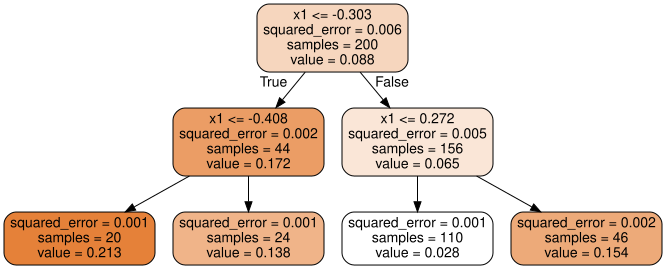

In [81]:
graph_file = IMAGES_PATH / "regression_tree.dot"

export_graphviz(
    tree_reg,
    out_file=str(graph_file),
    feature_names=["x1"],
    rounded=True,
    filled=True
)

graph = Source.from_file(graph_file)
graph


In [82]:
dt_reg = DecisionTreeRegressor(
    max_depth=3,
    random_state=42
)

dt_reg.fit(X_quad, y_quad)

dt_reg.tree_.threshold
tree_reg2.tree_.threshold


array([-0.30265072, -0.40830374, -0.45416115, -2.        , -2.        ,
       -0.37022041, -2.        , -2.        ,  0.27175756, -0.21270403,
       -2.        , -2.        ,  0.40399227, -2.        , -2.        ])

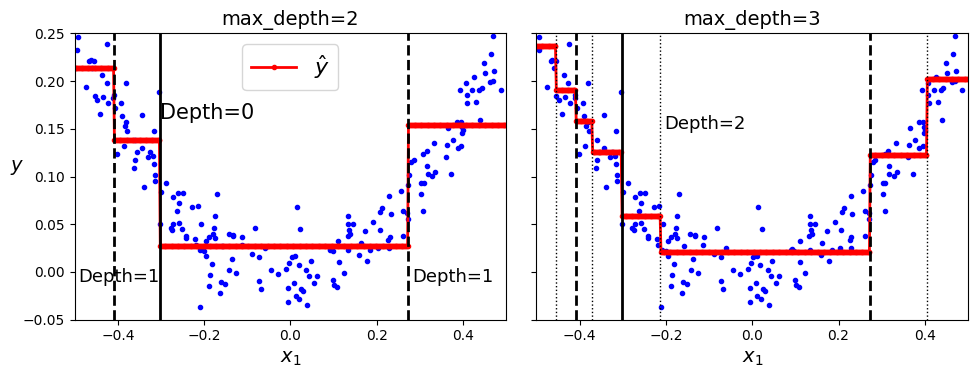

In [85]:
def draw_tree_regression(model, X_data, y_data, limits=(-0.5, 0.5, -0.05, 0.25)):
    x_vals = np.linspace(limits[0], limits[1], 500)[:, np.newaxis]
    y_vals = model.predict(x_vals)

    plt.axis(limits)
    plt.xlabel("$x_1$")
    plt.plot(X_data, y_data, "b.")
    plt.plot(x_vals, y_vals, "r.-", linewidth=2, label=r"$\hat{y}$")


fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
plt.sca(ax[0])
draw_tree_regression(tree_reg, X_quad, y_quad)

t0, t1_left, t1_right = tree_reg.tree_.threshold[[0, 1, 4]]
splits_lvl1 = [(t0, "k-"), (t1_left, "k--"), (t1_right, "k--")]

for s, ls in splits_lvl1:
    plt.plot([s, s], [-0.05, 0.25], ls, linewidth=2)

plt.text(t0, 0.16, "Depth=0", fontsize=15)
plt.text(t1_left + 0.01, -0.01, "Depth=1", ha="center", fontsize=13)
plt.text(t1_right + 0.01, -0.01, "Depth=1", fontsize=13)

plt.ylabel("$y$", rotation=0)
plt.legend(loc="upper center", fontsize=16)
plt.title("max_depth=2")
plt.sca(ax[1])
draw_tree_regression(tree_reg2, X_quad, y_quad)

t2 = tree_reg2.tree_.threshold[[2, 5, 9, 12]]

for s, ls in splits_lvl1:
    plt.plot([s, s], [-0.05, 0.25], ls, linewidth=2)

for s in t2:
    plt.plot([s, s], [-0.05, 0.25], "k:", linewidth=1)

plt.text(t2[2] + 0.01, 0.15, "Depth=2", fontsize=13)
plt.title("max_depth=3")


save_fig("tree_regression_plot")
plt.show()


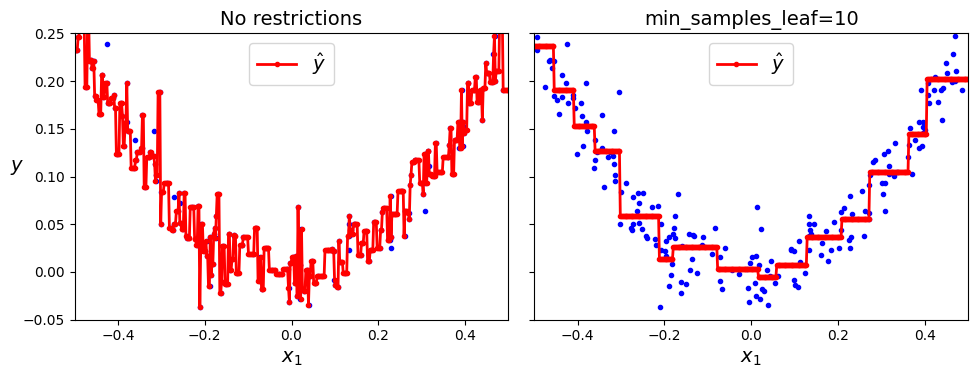

In [88]:
# extra code – this cell generates and saves Figure 6–6

from sklearn.tree import DecisionTreeRegressor
import numpy as np
import matplotlib.pyplot as plt

# Models
models = [
    ("No restrictions", DecisionTreeRegressor(random_state=42)),
    ("min_samples_leaf=10", DecisionTreeRegressor(random_state=42, min_samples_leaf=10))
]

# Fit models
for _, model in models:
    model.fit(X_quad, y_quad)

# Prediction grid
x_grid = np.linspace(-0.5, 0.5, 500).reshape(-1, 1)

# Create figure
fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
# Plot results
for ax, (title, model) in zip(axes, models):
    y_pred = model.predict(x_grid)
    
    ax.plot(X_quad, y_quad, "b.")
    ax.plot(x_grid, y_pred, "r.-", linewidth=2, label=r"$\hat{y}$")
    ax.axis([-0.5, 0.5, -0.05, 0.25])
    ax.set_xlabel("$x_1$")
    ax.set_title(title)
    ax.legend(loc="upper center")

axes[0].set_ylabel("$y$", rotation=0)

save_fig("tree_regression_regularization_plot")
plt.show()



# Sensitivity to axis orientation

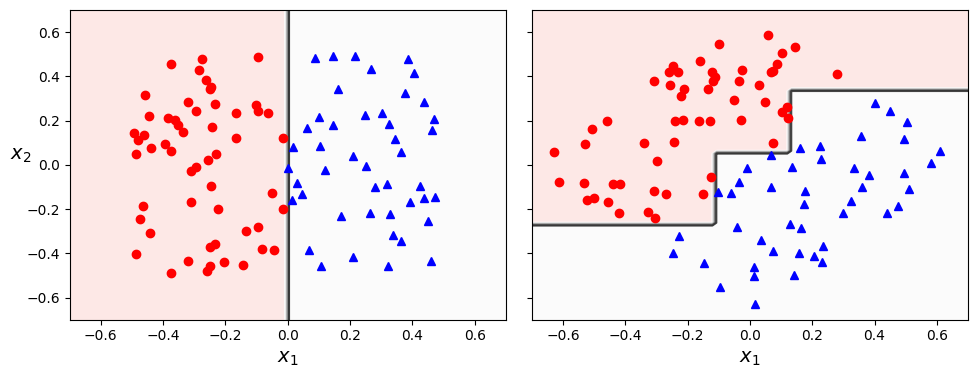

In [89]:
# extra code – this cell generates and saves Figure 6–7

np.random.seed(6)
X_square = np.random.rand(100, 2) - 0.5
y_square = (X_square[:, 0] > 0).astype(np.int64)

angle = np.pi / 4  # 45 degrees
rotation_matrix = np.array([[np.cos(angle), -np.sin(angle)],
                            [np.sin(angle), np.cos(angle)]])
X_rotated_square = X_square.dot(rotation_matrix)

tree_clf_square = DecisionTreeClassifier(random_state=42)
tree_clf_square.fit(X_square, y_square)
tree_clf_rotated_square = DecisionTreeClassifier(random_state=42)
tree_clf_rotated_square.fit(X_rotated_square, y_square)

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(axes[0])
plot_decision_boundary(tree_clf_square, X_square, y_square,
                       axes=[-0.7, 0.7, -0.7, 0.7], cmap="Pastel1")
plt.sca(axes[1])
plot_decision_boundary(tree_clf_rotated_square, X_rotated_square, y_square,
                       axes=[-0.7, 0.7, -0.7, 0.7], cmap="Pastel1")
plt.ylabel("")

save_fig("sensitivity_to_rotation_plot")
plt.show()

In [94]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

scaler = StandardScaler()
X_iris_scaled = scaler.fit_transform(X_iris)

pca = PCA()
X_iris_rotated = pca.fit_transform(X_iris_scaled)

tree_clf_pca = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_clf_pca.fit(X_iris_rotated, y_iris)


DecisionTreeClassifier(max_depth=2, random_state=42)

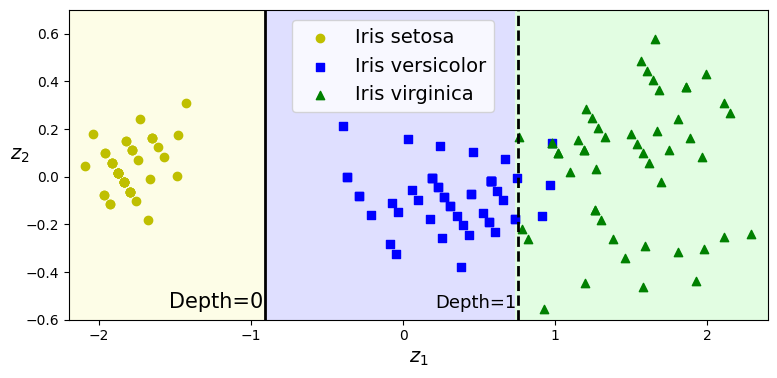

In [95]:
fig, ax = plt.subplots(figsize=(8, 4))

# define grid
x_vals = np.linspace(-2.2, 2.4, 100)
y_vals = np.linspace(-0.6, 0.7, 100)
Z0, Z1 = np.meshgrid(x_vals, y_vals)
grid_points = np.c_[Z0.ravel(), Z1.ravel()]

# predict over the grid
pred_labels = tree_clf_pca.predict(grid_points).reshape(Z0.shape)
ax.contourf(Z0, Z1, pred_labels, alpha=0.3, cmap=custom_cmap)

# plot iris points
markers = ("yo", "bs", "g^")
for i, (name, marker) in enumerate(zip(iris.target_names, markers)):
    ax.scatter(X_iris_rotated[y_iris == i, 0],
               X_iris_rotated[y_iris == i, 1],
               marker=marker[1], color=marker[0], label=f"Iris {name}")

# labels
ax.set_xlabel("$z_1$")
ax.set_ylabel("$z_2$", rotation=0)

# decision boundaries
th1, th2 = tree_clf_pca.tree_.threshold[[0, 2]]
ax.axvline(th1, color="k", linewidth=2)
ax.axvline(th2, color="k", linestyle="--", linewidth=2)
ax.text(th1 - 0.01, -0.55, "Depth=0", ha="right", fontsize=15)
ax.text(th2 - 0.01, -0.55, "Depth=1", ha="right", fontsize=13)

ax.set_xlim(-2.2, 2.4)
ax.set_ylim(-0.6, 0.7)
ax.legend(loc=(0.32, 0.67))

save_fig("pca_preprocessing_plot")
plt.show()


# Decision Trees Have High Variance

In [96]:
from sklearn.tree import DecisionTreeClassifier
tree_clf_tweaked = DecisionTreeClassifier(random_state=40, max_depth=2)
tree_clf_tweaked = tree_clf_tweaked.fit(X_iris, y_iris)


In [100]:
tree_clf_tweaked = DecisionTreeClassifier(max_depth=2, random_state=40)
tree_clf_tweaked.fit(X_iris, y_iris)
y_pred = tree_clf_tweaked.predict(X_iris_all).reshape(lengths.shape)


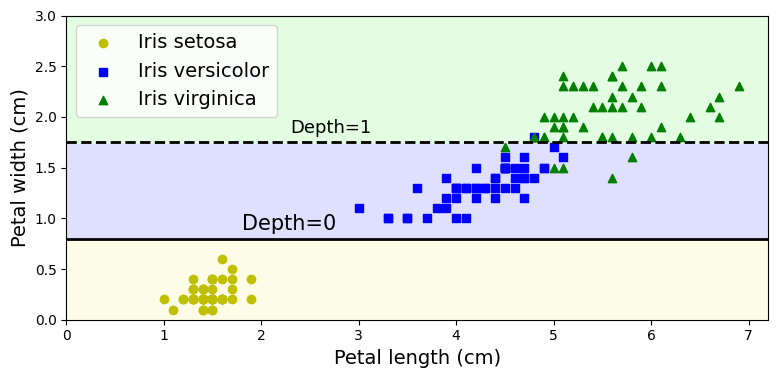

In [101]:
plt.figure(figsize=(8, 4))
plt.contourf(lengths, widths, y_pred, alpha=0.3, cmap=custom_cmap)
markers = ["yo", "bs", "g^"]
for idx, (name, marker) in enumerate(zip(iris.target_names, markers)):
    plt.scatter(X_iris[y_iris == idx, 0], X_iris[y_iris == idx, 1],
                c=marker[0], marker=marker[1], label=f"Iris {name}")
thresholds = tree_clf_tweaked.tree_.threshold
plt.hlines([thresholds[0], thresholds[2]], xmin=0, xmax=7.2,
           colors='k', linestyles=['-', '--'], linewidth=2)
plt.text(1.8, thresholds[0] + 0.05, "Depth=0", verticalalignment="bottom", fontsize=15)
plt.text(2.3, thresholds[2] + 0.05, "Depth=1", verticalalignment="bottom", fontsize=13)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.axis([0, 7.2, 0, 3])
plt.legend()
save_fig("decision_tree_high_variance_plot")
plt.show()


---

## Project notes and next steps
Compare tree depths using cross-validation, evaluate a confusion matrix, and contrast the tree with a linear baseline.

## Topics / hashtags
#MachineLearning #DecisionTrees #Classification #ScikitLearn #Python #ModelInterpretability #DataScience

## Feedback
Suggestions for improving the analysis, evaluation, or visualizations are welcome.
